# Fase 2 — Entendimento dos Dados

**Projeto:** Detecção de fraude em sinistros de automóvel — Quilha Seguros
**Fonte:** `data/raw/quilha_sinistros.csv` (60.000 sinistros, 17 colunas, 01/04/2026 a 31/08/2026)
**Objetivo da fase:** auditar a base antes de qualquer modelagem — dimensões, tipos,
dicionário, distribuição do alvo, nulos, problemas de qualidade e estatística descritiva.

**Regra de ouro desta fase:** a base é lida exatamente como foi entregue. Todo tratamento
acontece em código, nenhuma edição é feita no CSV.

In [1]:
# =============================================================================
# Configuração do ambiente, semente e caminhos do projeto
# =============================================================================
import matplotlib

# Fora do Jupyter (execução como script .py) usamos backend sem interface gráfica:
# assim o arquivo roda em qualquer máquina, inclusive sem tela.
INTERATIVO = "get_ipython" in globals()
if not INTERATIVO:
    matplotlib.use("Agg")

from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from matplotlib import pyplot as plt

# Semente global do projeto: garante reprodutibilidade de qualquer etapa aleatória
# (divisão de treino/teste, modelos, amostragens). Ainda não há aleatoriedade nesta fase.
SEED = 42


def encontrar_raiz(inicio: Path) -> Path:
    """Sobe na árvore de diretórios até encontrar a raiz do projeto (pyproject.toml)."""
    for pasta in [inicio.resolve(), *inicio.resolve().parents]:
        if (pasta / "pyproject.toml").exists():
            return pasta
    raise FileNotFoundError("Raiz do projeto não encontrada (pyproject.toml ausente).")


RAIZ = encontrar_raiz(Path.cwd())
ARQ_BRUTO = RAIZ / "data" / "raw" / "quilha_sinistros.csv"
PASTA_FIGURAS = RAIZ / "reports" / "figures"
PASTA_FIGURAS.mkdir(parents=True, exist_ok=True)

# Opções de exibição das tabelas
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda valor: f"{valor:,.2f}")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.titlesize"] = 11

print(f"Raiz do projeto : {RAIZ}")
print(f"Arquivo de base : {ARQ_BRUTO}")
print(f"Semente (SEED)  : {SEED}")

Raiz do projeto : C:\Users\flavi\Documents\GitHub\Auto-Insurance-Fraud
Arquivo de base : C:\Users\flavi\Documents\GitHub\Auto-Insurance-Fraud\data\raw\quilha_sinistros.csv
Semente (SEED)  : 42


## 1. Carga da base e dimensões

In [2]:
# Leitura em duas etapas, de propósito:
#   1) `dtype=str` — traz a base crua como texto, sem o pandas "adivinhar" formatos.
#      Se deixássemos inferir, o `valor_reclamado` com vírgula decimal viraria texto
#      silenciosamente e nós não enxergaríamos o problema.
#   2) tipagem explícita — só depois de auditar o formato original.
base_bruta = pd.read_csv(ARQ_BRUTO, dtype=str)

print(f"Linhas  : {base_bruta.shape[0]:,}")
print(f"Colunas : {base_bruta.shape[1]}")
print()
print("Confere com o Anexo 2 do case (60.000 linhas x 17 colunas): "
      f"{base_bruta.shape == (60000, 17)}")
print()
print("Colunas da base:")
print(list(base_bruta.columns))
print()
print("Primeiras 5 linhas da base crua:")
display(base_bruta.head())

Linhas  : 60,000
Colunas : 17

Confere com o Anexo 2 do case (60.000 linhas x 17 colunas): True

Colunas da base:
['id_sinistro', 'data_ocorrencia', 'hora_ocorrencia', 'data_abertura', 'canal_abertura', 'tipo_sinistro', 'uf', 'idade_segurado', 'dias_de_apolice', 'sinistros_12m', 'idade_veiculo', 'valor_fipe', 'valor_reclamado', 'boletim_ocorrencia', 'terceiro_identificado', 'valor_indenizado', 'fraude']

Primeiras 5 linhas da base crua:


,id_sinistro,data_ocorrencia,hora_ocorrencia,data_abertura,canal_abertura,tipo_sinistro,uf,idade_segurado,dias_de_apolice,sinistros_12m,idade_veiculo,valor_fipe,valor_reclamado,boletim_ocorrencia,terceiro_identificado,valor_indenizado,fraude
0,SIN-26-139209,2026-07-18,13:53,2026-07-18,App,Roubo/Furto,RJ,47,1295,0,10,20900.0,"20387,95",Sim,Não se aplica,20387.95,0
1,SIN-26-158479,2026-07-11,10:28,2026-07-12,Central 0800,Colisão,MG,19,266,0,5,85600.0,"6636,04",Sim,Sim,2356.04,0
2,SIN-26-114996,2026-06-13,20:07,2026-06-13,App,Colisão,TO,41,1086,0,2,96900.0,"3120,90",NaN,Não,0.0,0
3,SIN-26-129952,2026-05-13,15:15,2026-05-14,App,Vidros,SP,49,365,0,2,116600.0,"1133,06",Não,Não se aplica,833.06,0
4,SIN-26-141496,2026-05-26,15:11,2026-05-26,Corretor,Terceiros,RS,35,1522,0,2,39100.0,"9944,19",Não,Sim,9944.19,0


## 2. Tipos, dicionário de dados e tratamento necessário

Primeiro auditamos o **formato original** (o que o CSV realmente contém), depois aplicamos
a tipagem correta e conferimos se a conversão **não criou nenhum nulo novo**.

In [3]:
print("Tipos na leitura bruta (tudo texto, por decisão nossa):")
print(base_bruta.dtypes.to_string())

Tipos na leitura bruta (tudo texto, por decisão nossa):
id_sinistro              str
data_ocorrencia          str
hora_ocorrencia          str
data_abertura            str
canal_abertura           str
tipo_sinistro            str
uf                       str
idade_segurado           str
dias_de_apolice          str
sinistros_12m            str
idade_veiculo            str
valor_fipe               str
valor_reclamado          str
boletim_ocorrencia       str
terceiro_identificado    str
valor_indenizado         str
fraude                   str


In [4]:
# Dicionário de dados: significado, unidade e tratamento necessário por coluna
dicionario = pd.DataFrame(
    [
        ("id_sinistro", "Texto", "Identificador único do sinistro (chave)", "—",
         "Nenhum. Chave de controle; não entra no modelo."),
        ("data_ocorrencia", "Data", "Data do evento, informada pelo segurado", "AAAA-MM-DD",
         "Converter texto em data."),
        ("hora_ocorrencia", "Texto (HH:MM)", "Hora do evento, informada pelo segurado", "HH:MM",
         "Validar formato; extrair hora como atributo na Fase 3."),
        ("data_abertura", "Data", "Data em que o sinistro foi comunicado à Quilha", "AAAA-MM-DD",
         "Converter texto em data. Base da separação temporal treino/teste."),
        ("canal_abertura", "Categórica", "Canal de comunicação: App, Corretor, Central 0800", "—",
         "Padronizar categorias (espaços, maiúsculas)."),
        ("tipo_sinistro", "Categórica", "Colisão, Vidros, Roubo/Furto, Terceiros, Alagamento, Incêndio", "—",
         "Padronizar categorias."),
        ("uf", "Categórica", "Estado (UF) onde ocorreu o sinistro", "UF (2 letras)",
         "Padronizar (maiúsculas, sem espaços). Uso condicionado à Pergunta 1."),
        ("idade_segurado", "Inteiro", "Idade do segurado principal na data do sinistro", "anos",
         "Converter texto em inteiro."),
        ("dias_de_apolice", "Inteiro", "Dias desde a primeira contratação do segurado com a Quilha", "dias",
         "Converter texto em inteiro."),
        ("sinistros_12m", "Inteiro", "Sinistros abertos pelo mesmo segurado nos 12 meses anteriores", "contagem",
         "Converter texto em inteiro."),
        ("idade_veiculo", "Inteiro", "Anos desde a fabricação do veículo", "anos",
         "Converter texto em inteiro."),
        ("valor_fipe", "Numérico", "Valor de referência do veículo na tabela FIPE", "R$",
         "Converter texto em decimal (ponto)."),
        ("valor_reclamado", "Numérico", "Valor pedido na abertura: orçamento de reparo ou valor do veículo", "R$",
         "Vírgula decimal → ponto, depois decimal."),
        ("boletim_ocorrencia", "Categórica", "Se o segurado apresentou boletim de ocorrência (Sim/Não)", "—",
         "Há campos em branco: tratar como categoria própria."),
        ("terceiro_identificado", "Categórica", "Há outro veículo ou pessoa identificada (Sim/Não/Não se aplica)", "—",
         "Padronizar categorias (inclui 'Não se aplica')."),
        ("valor_indenizado", "Numérico", "Valor pago no encerramento do sinistro", "R$",
         "Converter para decimal. EXCLUIR do modelo: só existe após a decisão (vazamento)."),
        ("fraude", "Binário", "1 = fraude confirmada pela auditoria; 0 = sinistro legítimo", "0/1",
         "Variável-alvo."),
    ],
    columns=["coluna", "tipo", "significado", "unidade", "tratamento_necessario"],
)
display(dicionario)

,coluna,tipo,significado,unidade,tratamento_necessario
0,id_sinistro,Texto,Identificador único do sinistro (chave),—,Nenhum. Chave de controle; não entra no modelo.
1,data_ocorrencia,Data,"Data do evento, informada pelo segurado",AAAA-MM-DD,Converter texto em data.
2,hora_ocorrencia,Texto (HH:MM),"Hora do evento, informada pelo segurado",HH:MM,Validar formato; extrair hora como atributo na...
3,data_abertura,Data,Data em que o sinistro foi comunicado à Quilha,AAAA-MM-DD,Converter texto em data. Base da separação tem...
4,canal_abertura,Categórica,"Canal de comunicação: App, Corretor, Central 0800",—,"Padronizar categorias (espaços, maiúsculas)."
5,tipo_sinistro,Categórica,"Colisão, Vidros, Roubo/Furto, Terceiros, Alaga...",—,Padronizar categorias.
6,uf,Categórica,Estado (UF) onde ocorreu o sinistro,UF (2 letras),"Padronizar (maiúsculas, sem espaços). Uso cond..."
7,idade_segurado,Inteiro,Idade do segurado principal na data do sinistro,anos,Converter texto em inteiro.
8,dias_de_apolice,Inteiro,Dias desde a primeira contratação do segurado ...,dias,Converter texto em inteiro.
9,sinistros_12m,Inteiro,Sinistros abertos pelo mesmo segurado nos 12 m...,contagem,Converter texto em inteiro.


In [5]:
# Tipagem explícita, coluna a coluna. Usamos coerce + contagem de falhas em vez de
# deixar estourar exceção: assim, se houver valor sujo, ele aparece como nulo e é
# reportado, em vez de derrubar o notebook sem explicação.
base = base_bruta.copy()

# valor_reclamado é a ÚNICA coluna com vírgula decimal (Anexo 2 do case)
base["valor_reclamado"] = pd.to_numeric(
    base["valor_reclamado"].str.replace(",", ".", regex=False), errors="coerce"
)

COLS_DECIMAIS = ["valor_fipe", "valor_indenizado"]
COLS_INTEIRAS = ["idade_segurado", "dias_de_apolice", "sinistros_12m", "idade_veiculo", "fraude"]
COLS_DATA = ["data_ocorrencia", "data_abertura"]

for col in COLS_DECIMAIS:
    base[col] = pd.to_numeric(base[col], errors="coerce")
for col in COLS_INTEIRAS:
    base[col] = pd.to_numeric(base[col], errors="coerce").astype("Int64")
for col in COLS_DATA:
    base[col] = pd.to_datetime(base[col], format="%Y-%m-%d", errors="coerce")

print("Tipos após a conversão:")
print(base.dtypes.to_string())

Tipos após a conversão:


id_sinistro                         str
data_ocorrencia          datetime64[us]
hora_ocorrencia                     str
data_abertura            datetime64[us]
canal_abertura                      str
tipo_sinistro                       str
uf                                  str
idade_segurado                    Int64
dias_de_apolice                   Int64
sinistros_12m                     Int64
idade_veiculo                     Int64
valor_fipe                      float64
valor_reclamado                 float64
boletim_ocorrencia                  str
terceiro_identificado               str
valor_indenizado                float64
fraude                            Int64


In [6]:
# Controle de qualidade da conversão: nenhum valor pode ter virado nulo por erro de formato
nulos_antes = base_bruta.isna().sum()
nulos_depois = base.isna().sum()
nulos_criados = (nulos_depois - nulos_antes)
nulos_criados = nulos_criados[nulos_criados > 0]

print("Nulos criados pela conversão de tipos (esperado: nenhum):")
if nulos_criados.empty:
    print("  Nenhum. Todas as colunas foram convertidas sem perda de valor.")
else:
    display(nulos_criados.to_frame("nulos_criados_na_conversao"))

Nulos criados pela conversão de tipos (esperado: nenhum):
  Nenhum. Todas as colunas foram convertidas sem perda de valor.


In [7]:
# Verificação de formato da hora, que permanece texto nesta fase
padrao_hora = r"^([01]\d|2[0-3]):[0-5]\d$"
hora_valida = base_bruta["hora_ocorrencia"].str.match(padrao_hora, na=False)
print(f"hora_ocorrencia no formato HH:MM válido : {hora_valida.sum():,} de {len(base_bruta):,}")
print(f"hora_ocorrencia fora do padrão           : {(~hora_valida).sum():,}")
if (~hora_valida).any():
    print("Exemplos fora do padrão:")
    print(base_bruta.loc[~hora_valida, "hora_ocorrencia"].head(10).to_string())

hora_ocorrencia no formato HH:MM válido : 60,000 de 60,000
hora_ocorrencia fora do padrão           : 0


## 3. Variável-alvo: contagem, percentual e proporção

In [8]:
contagem_alvo = base["fraude"].value_counts().sort_index()
percentual_alvo = base["fraude"].value_counts(normalize=True).sort_index().mul(100)

tabela_alvo = pd.DataFrame({
    "classe": ["0 — Legítimo", "1 — Fraude"],
    "contagem": contagem_alvo.values,
    "percentual (%)": percentual_alvo.round(2).values,
})
display(tabela_alvo)

n_legitimo = int(contagem_alvo.loc[0])
n_fraude = int(contagem_alvo.loc[1])
taxa_fraude = n_fraude / len(base)

print(f"Taxa de fraude da base        : {taxa_fraude:.4f}  ({taxa_fraude * 100:.2f}%)")
print(f"Proporção                     : 1 fraude confirmada para {n_legitimo / n_fraude:.2f} sinistros legítimos")
print(f"Proporção (arredondada)       : 1 : {round(n_legitimo / n_fraude)}")
print(f"Razão de desbalanceamento     : {n_legitimo / n_fraude:.0f} legítimos por fraude")

,classe,contagem,percentual (%)
0,0 — Legítimo,58520,97.53
1,1 — Fraude,1480,2.47


Taxa de fraude da base        : 0.0247  (2.47%)
Proporção                     : 1 fraude confirmada para 39.54 sinistros legítimos
Proporção (arredondada)       : 1 : 40
Razão de desbalanceamento     : 40 legítimos por fraude


In [9]:
# Recorte mensal: o case informa ~12.000 sinistros/mês e a auditoria cobre 5 meses.
# Esse número é decisivo, porque compara o volume de fraude com a capacidade de perícia.
MESES_DA_JANELA = 5  # janela auditada: 01/04/2026 a 31/08/2026

print(f"Janela auditada             : 01/04/2026 a 31/08/2026 ({MESES_DA_JANELA} meses)")
print(f"Sinistros por mês           : {len(base) / MESES_DA_JANELA:,.0f}")
print(f"Fraudes por mês             : {n_fraude / MESES_DA_JANELA:,.1f}")
print(f"Capacidade de perícia       : 900/mês")
print(f"Fraudes por mês / capacidade: {n_fraude / MESES_DA_JANELA / 900 * 100:.1f}%")

Janela auditada             : 01/04/2026 a 31/08/2026 (5 meses)
Sinistros por mês           : 12,000
Fraudes por mês             : 296.0
Capacidade de perícia       : 900/mês
Fraudes por mês / capacidade: 32.9%


## 4. A acurácia do "modelo de uma linha" (chutar sempre a classe majoritária)

In [10]:
# Um classificador que responde "ninguém frauda" para todo mundo acerta exatamente
# a proporção da classe majoritária. Não é mérito: é a inércia da base.
acuracia_dummy = (base["fraude"] == 0).mean()

print("Modelo ingênuo: prever SEMPRE 'legítimo' (classe majoritária)")
print(f"  Acertos (fraudes não detectadas): {n_legitimo:,}")
print(f"  Erros   (fraudes ignoradas)     : {n_fraude:,}")
print(f"  Acurácia                        : {acuracia_dummy:.4f}  ({acuracia_dummy * 100:.2f}%)")
print()
print(f"Ou seja: sem aprender NADA, esse 'modelo' já tira {acuracia_dummy * 100:.2f}% de acurácia,")
print(f"mas deixa {n_fraude:,} fraudes passarem — exatamente o que queremos evitar.")

Modelo ingênuo: prever SEMPRE 'legítimo' (classe majoritária)
  Acertos (fraudes não detectadas): 58,520
  Erros   (fraudes ignoradas)     : 1,480
  Acurácia                        : 0.9753  (97.53%)

Ou seja: sem aprender NADA, esse 'modelo' já tira 97.53% de acurácia,
mas deixa 1,480 fraudes passarem — exatamente o que queremos evitar.


## 5. Métricas do projeto: o que cada uma mede e com que cuidado

In [11]:
metricas = pd.DataFrame(
    [
        ("Acurácia", "Percentual de acertos sobre o total.",
         "INUTILIZÁVEL aqui. Um modelo que nunca aponta fraude já supera 90%. Não usar como métrica de decisão."),
        ("ROC AUC", "Probabilidade de o modelo dar nota maior a um sinistro fraudulento do que a um legítimo. "
                    "Independe do ponto de corte.",
         "Otimista em evento raro: a taxa de falsos positivos é diluída por milhares de legítimos. "
         "Serve para comparar modelos, não para decidir."),
        ("PR AUC (average precision)", "Resume o equilíbrio entre precisão e cobertura ao longo de todos os cortes.",
         "A referência NÃO é 0,5: é a taxa base da fraude. Depende da prevalência — só comparar na mesma base."),
        ("Precisão@900", "Dos 900 sinistros enviados à perícia, quantos eram fraude de verdade.",
         "É a métrica que vira dinheiro sob capacidade fixa. Zerada se o desempate piorar a fila."),
        ("Cobertura@900 (recall)", "Das fraudes existentes, quantas entraram na fila de perícia.",
         "O teto é limitado pela capacidade: com 900 vagas, não há como cobrir mais do que isso por mês."),
        ("Resultado(k) — negócio", "21.700 × fraudes periciadas − 700 × k. Saldo líquido da política.",
         "Depende do custo unitário da perícia e da premissa de que a perícia sempre encontra a fraude."),
    ],
    columns=["métrica", "o que mede", "cuidado principal"],
)
display(metricas)

,métrica,o que mede,cuidado principal
0,Acurácia,Percentual de acertos sobre o total.,INUTILIZÁVEL aqui. Um modelo que nunca aponta ...
1,ROC AUC,Probabilidade de o modelo dar nota maior a um ...,Otimista em evento raro: a taxa de falsos posi...
2,PR AUC (average precision),Resume o equilíbrio entre precisão e cobertura...,"A referência NÃO é 0,5: é a taxa base da fraud..."
3,Precisão@900,"Dos 900 sinistros enviados à perícia, quantos ...",É a métrica que vira dinheiro sob capacidade f...
4,Cobertura@900 (recall),"Das fraudes existentes, quantas entraram na fi...",O teto é limitado pela capacidade: com 900 vag...
5,Resultado(k) — negócio,21.700 × fraudes periciadas − 700 × k. Saldo l...,Depende do custo unitário da perícia e da prem...


## 6. Valores nulos: quantidade e percentual

In [12]:
qtd_nulos = base_bruta.isna().sum()
tabela_nulos = pd.DataFrame({
    "coluna": qtd_nulos.index,
    "qtd_nulos": qtd_nulos.values,
    "pct_nulos (%)": (qtd_nulos.values / len(base_bruta) * 100).round(2),
})
tabela_nulos = tabela_nulos[tabela_nulos["qtd_nulos"] > 0].reset_index(drop=True)

print("Colunas com valores nulos:")
display(tabela_nulos)

if not tabela_nulos.empty:
    pior = tabela_nulos.sort_values("pct_nulos (%)", ascending=False).iloc[0]
    print(f"Coluna mais afetada: {pior['coluna']} — {pior['qtd_nulos']:,} nulos "
          f"({pior['pct_nulos (%)']:.2f}% da base)")

Colunas com valores nulos:


,coluna,qtd_nulos,pct_nulos (%)
0,boletim_ocorrencia,2899,4.83


Coluna mais afetada: boletim_ocorrencia — 2,899 nulos (4.83% da base)


## 7. Dá para simplesmente descartar as linhas com nulo?

In [13]:
linhas_com_nulo = base_bruta.isna().any(axis=1)
n_linhas_com_nulo = int(linhas_com_nulo.sum())

fraudes_totais = int(contagem_alvo.loc[1])
fraudes_em_linhas_com_nulo = int((base.loc[linhas_com_nulo, "fraude"] == 1).sum())

print("Impacto de descartar toda linha com pelo menos um campo em branco:")
print(f"  Linhas (sinistros) descartadas : {n_linhas_com_nulo:,} "
      f"({n_linhas_com_nulo / len(base_bruta) * 100:.2f}% da base)")
print(f"  Fraudes perdidas no descarte   : {fraudes_em_linhas_com_nulo:,} "
      f"({fraudes_em_linhas_com_nulo / fraudes_totais * 100:.2f}% de todas as fraudes)")
print(f"  Custo dessas fraudes, se pagas : R$ {fraudes_em_linhas_com_nulo * 21700:,.2f} "
      f"(21.700 x fraudes descartadas)")
print()
print("Observação de escopo: a base tem uma linha por sinistro e NÃO possui identificador de")
print("segurado (CPF/cliente). Logo, não é possível contar 'clientes' perdidos em sentido estrito;")
print("a única medida disponível é de sinistros — mesma ordem de grandeza, unidade diferente.")

Impacto de descartar toda linha com pelo menos um campo em branco:
  Linhas (sinistros) descartadas : 2,899 (4.83% da base)
  Fraudes perdidas no descarte   : 94 (6.35% de todas as fraudes)
  Custo dessas fraudes, se pagas : R$ 2,039,800.00 (21.700 x fraudes descartadas)

Observação de escopo: a base tem uma linha por sinistro e NÃO possui identificador de
segurado (CPF/cliente). Logo, não é possível contar 'clientes' perdidos em sentido estrito;
a única medida disponível é de sinistros — mesma ordem de grandeza, unidade diferente.


## 8. Outros problemas de qualidade na base

Bateria de verificações: chaves duplicadas, datas incoerentes, valores impossíveis,
categorias fora do padrão e incoerências entre colunas.

In [14]:
print("=" * 78)
print("8.1 Chave primária")
print("=" * 78)
dup_id = int(base_bruta["id_sinistro"].duplicated().sum())
dup_linha = int(base_bruta.duplicated().sum())
print(f"id_sinistro duplicados      : {dup_id}")
print(f"linhas inteiramente iguais  : {dup_linha}")

8.1 Chave primária


id_sinistro duplicados      : 0
linhas inteiramente iguais  : 0


In [15]:
print("=" * 78)
print("8.2 Datas: janela do case (2026-04-01 a 2026-08-31) e coerência")
print("=" * 78)
INICIO, FIM = pd.Timestamp("2026-04-01"), pd.Timestamp("2026-08-31")

for col in COLS_DATA:
    fora = ((base[col] < INICIO) | (base[col] > FIM)).sum()
    print(f"{col:18s} fora da janela: {fora:>6,}   "
          f"mín={base[col].min().date()}  máx={base[col].max().date()}")

ocorrencia_apos_abertura = (base["data_ocorrencia"] > base["data_abertura"]).sum()
print(f"\ndata_ocorrencia posterior a data_abertura: {ocorrencia_apos_abertura:,}")
atraso_dias = (base["data_abertura"] - base["data_ocorrencia"]).dt.days
print(f"atraso entre ocorrência e abertura (dias): mín={atraso_dias.min()}, "
      f"mediana={atraso_dias.median():.0f}, máx={atraso_dias.max()}")

8.2 Datas: janela do case (2026-04-01 a 2026-08-31) e coerência
data_ocorrencia    fora da janela:    688   mín=2026-03-02  máx=2026-08-31
data_abertura      fora da janela:      0   mín=2026-04-01  máx=2026-08-31

data_ocorrencia posterior a data_abertura: 0
atraso entre ocorrência e abertura (dias): mín=0, mediana=1, máx=45


In [16]:
print("=" * 78)
print("8.3 Valores monetários: zeros, negativos e incoerências")
print("=" * 78)
for col in ["valor_fipe", "valor_reclamado", "valor_indenizado"]:
    s = base[col]
    print(f"{col:18s} mín={s.min():>12,.2f}  máx={s.max():>14,.2f}  "
          f"zeros={int((s == 0).sum()):>6,}  negativos={int((s < 0).sum()):>4,}")

indenizado_maior = int((base["valor_indenizado"] > base["valor_reclamado"]).sum())
print(f"\nvalor_indenizado MAIOR que valor_reclamado : {indenizado_maior:,}")
reclamado_maior_fipe = int((base["valor_reclamado"] > base["valor_fipe"]).sum())
print(f"valor_reclamado MAIOR que valor_fipe       : {reclamado_maior_fipe:,} "
      f"({reclamado_maior_fipe / len(base) * 100:.2f}%)")

8.3 Valores monetários: zeros, negativos e incoerências
valor_fipe         mín=   15,000.00  máx=    420,000.00  zeros=     0  negativos=   0
valor_reclamado    mín=      184.08  máx=    416,670.02  zeros=     0  negativos=   0
valor_indenizado   mín=        0.00  máx=    416,670.02  zeros= 8,066  negativos=   0

valor_indenizado MAIOR que valor_reclamado : 0
valor_reclamado MAIOR que valor_fipe       : 117 (0.19%)


In [17]:
print("=" * 78)
print("8.4 Colunas numéricas: faixas implausíveis")
print("=" * 78)
faixas = {
    "idade_segurado": (18, 100, "anos"),
    "dias_de_apolice": (0, 365 * 18, "dias"),
    "sinistros_12m": (0, 12, "sinistros"),
    "idade_veiculo": (0, 60, "anos"),
}
for col, (minimo, maximo, unidade) in faixas.items():
    s = base[col]
    fora = int(((s < minimo) | (s > maximo)).sum())
    print(f"{col:18s} mín={int(s.min()):>6}  máx={int(s.max()):>6}  "
          f"fora de [{minimo}, {maximo}] {unidade}: {fora:,}")

8.4 Colunas numéricas: faixas implausíveis
idade_segurado     mín=    18  máx=    85  fora de [18, 100] anos: 0
dias_de_apolice    mín=     0  máx=  5000  fora de [0, 6570] dias: 0
sinistros_12m      mín=     0  máx=     4  fora de [0, 12] sinistros: 0
idade_veiculo      mín=     0  máx=    25  fora de [0, 60] anos: 0


In [18]:
print("=" * 78)
print("8.5 Colunas categóricas: categorias existentes e padronização")
print("=" * 78)
COLS_CATEGORICAS = ["canal_abertura", "tipo_sinistro", "uf", "boletim_ocorrencia", "terceiro_identificado"]
for col in COLS_CATEGORICAS:
    valores = base_bruta[col].dropna().unique()
    com_espaco = int(base_bruta[col].dropna().str.contains(r"^\s|\s$", regex=True).sum())
    print(f"\n{col} — {len(valores)} categorias distintas | espaços nas pontas: {com_espaco}")
    print("  " + " | ".join(sorted(map(str, valores))))

8.5 Colunas categóricas: categorias existentes e padronização

canal_abertura — 3 categorias distintas | espaços nas pontas: 0
  App | Central 0800 | Corretor



tipo_sinistro — 6 categorias distintas | espaços nas pontas: 0


  Alagamento | Colisão | Incêndio | Roubo/Furto | Terceiros | Vidros



uf — 27 categorias distintas | espaços nas pontas: 0
  AC | AL | AM | AP | BA | CE | DF | ES | GO | MA | MG | MS | MT | PA | PB | PE | PI | PR | RJ | RN | RO | RR | RS | SC | SE | SP | TO

boletim_ocorrencia — 2 categorias distintas | espaços nas pontas: 0
  Não | Sim

terceiro_identificado — 3 categorias distintas | espaços nas pontas: 0
  Não | Não se aplica | Sim


In [19]:
print("=" * 78)
print("8.6 Estrutura de 'terceiro_identificado' por tipo de sinistro")
print("=" * 78)
print("Uso de 'terceiro_identificado' por tipo de sinistro:")
cruzamento = pd.crosstab(base_bruta["tipo_sinistro"], base_bruta["terceiro_identificado"], dropna=False)
display(cruzamento)

8.6 Estrutura de 'terceiro_identificado' por tipo de sinistro
Uso de 'terceiro_identificado' por tipo de sinistro:


terceiro_identificado,Não,Não se aplica,Sim
tipo_sinistro,,,
Alagamento,0,3002,0
Colisão,11668,0,19775
Incêndio,0,1835,0
Roubo/Furto,0,5908,0
Terceiros,0,0,5842
Vidros,0,11970,0


In [20]:
print("=" * 78)
print("8.7 valor_indenizado = 0: sinistros sem pagamento e relação com a fraude")
print("=" * 78)
sem_pagamento = base["valor_indenizado"] == 0
print(f"sinistros com valor_indenizado = 0 : {int(sem_pagamento.sum()):,} "
      f"({sem_pagamento.mean() * 100:.2f}%)")
print(f"  desses, marcados como fraude     : {int((sem_pagamento & (base['fraude'] == 1)).sum()):,}")
print(f"  desses, marcados como legítimos  : {int((sem_pagamento & (base['fraude'] == 0)).sum()):,}")
print(f"\ntaxa de fraude entre os sem pagamento : "
      f"{base.loc[sem_pagamento, 'fraude'].mean() * 100:.2f}%")
print(f"taxa de fraude entre os com pagamento : "
      f"{base.loc[~sem_pagamento, 'fraude'].mean() * 100:.2f}%")

8.7 valor_indenizado = 0: sinistros sem pagamento e relação com a fraude
sinistros com valor_indenizado = 0 : 8,066 (13.44%)
  desses, marcados como fraude     : 1,401
  desses, marcados como legítimos  : 6,665

taxa de fraude entre os sem pagamento : 17.37%
taxa de fraude entre os com pagamento : 0.15%


## 9. Estatística descritiva

In [21]:
COLS_NUMERICAS = ["idade_segurado", "dias_de_apolice", "sinistros_12m", "idade_veiculo",
                  "valor_fipe", "valor_reclamado", "valor_indenizado"]

descritiva = base[COLS_NUMERICAS].describe().T
descritiva["amplitude"] = descritiva["max"] - descritiva["min"]
descritiva["assimetria"] = base[COLS_NUMERICAS].skew()
descritiva = descritiva[["count", "min", "25%", "50%", "75%", "max", "mean", "std", "amplitude", "assimetria"]]
descritiva.columns = ["contagem", "mín", "25%", "mediana", "75%", "máx", "média", "desvio", "amplitude", "assimetria"]
print("Estatística descritiva das variáveis numéricas:")
display(descritiva.round(2))

Estatística descritiva das variáveis numéricas:


,contagem,mín,25%,mediana,75%,máx,média,desvio,amplitude,assimetria
idade_segurado,"60,000.00",18.00,35.00,44.00,53.00,85.00,44.19,12.75,67.00,0.11
dias_de_apolice,"60,000.00",0.00,365.00,882.00,"1,456.00","5,000.00","1,059.65",869.00,"5,000.00",1.50
sinistros_12m,"60,000.00",0.00,0.00,0.00,0.00,4.00,0.22,0.47,4.00,2.17
idade_veiculo,"60,000.00",0.00,3.00,5.00,8.00,25.00,6.15,4.11,25.00,1.24
valor_fipe,"60,000.00","15,000.00","39,800.00","58,500.00","83,800.00","420,000.00","66,404.75","37,879.94","405,000.00",1.66
valor_reclamado,"60,000.00",184.08,"2,220.61","5,824.76","15,527.51","416,670.02","15,374.31","24,897.06","416,485.94",3.51
valor_indenizado,"60,000.00",0.00,721.98,"2,741.18","10,961.65","416,670.02","12,455.42","24,568.12","416,670.02",3.71


In [22]:
print("Estatística descritiva das variáveis categóricas (moda, frequência e nº de categorias):")
desc_cat = base[COLS_CATEGORICAS].astype("string").describe().T
display(desc_cat)

Estatística descritiva das variáveis categóricas (moda, frequência e nº de categorias):


,count,unique,top,freq
canal_abertura,60000,3,App,26759
tipo_sinistro,60000,6,Colisão,31443
uf,60000,27,SP,17040
boletim_ocorrencia,57101,2,Sim,29131
terceiro_identificado,60000,3,Sim,25617


In [23]:
print("Distribuição das categorias (contagem e percentual):")
for col in COLS_CATEGORICAS:
    tabela = (
        base[col].fillna("(em branco)").value_counts()
        .to_frame("contagem")
        .assign(**{"percentual (%)": lambda d: (d["contagem"] / len(base) * 100).round(2)})
    )
    print(f"\n--- {col} ---")
    display(tabela)

Distribuição das categorias (contagem e percentual):

--- canal_abertura ---


,contagem,percentual (%)
canal_abertura,,
App,26759,44.60
Corretor,20899,34.83
Central 0800,12342,20.57



--- tipo_sinistro ---


,contagem,percentual (%)
tipo_sinistro,,
Colisão,31443,52.40
Vidros,11970,19.95
Roubo/Furto,5908,9.85
Terceiros,5842,9.74
Alagamento,3002,5.00
Incêndio,1835,3.06



--- uf ---


,contagem,percentual (%)
uf,,
SP,17040,28.40
MG,6898,11.50
RJ,5017,8.36
RS,4326,7.21
PR,4265,7.11
SC,3053,5.09
GO,2557,4.26
BA,2383,3.97
PE,1836,3.06



--- boletim_ocorrencia ---


,contagem,percentual (%)
boletim_ocorrencia,,
Sim,29131,48.55
Não,27970,46.62
(em branco),2899,4.83



--- terceiro_identificado ---


,contagem,percentual (%)
terceiro_identificado,,
Sim,25617,42.70
Não se aplica,22715,37.86
Não,11668,19.45


## 10. Visualizações

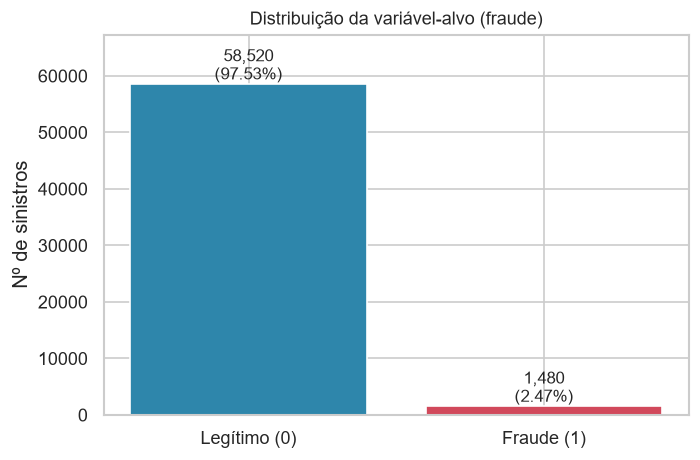

In [24]:
# Figura 1 — distribuição do alvo
fig, eixo = plt.subplots(figsize=(6, 4))
rotulos = ["Legítimo (0)", "Fraude (1)"]
valores = [n_legitimo, n_fraude]
barras = eixo.bar(rotulos, valores, color=["#2E86AB", "#D1495B"])
for barra, valor in zip(barras, valores):
    eixo.text(barra.get_x() + barra.get_width() / 2, valor, f"{valor:,}\n({valor / len(base) * 100:.2f}%)",
              ha="center", va="bottom", fontsize=10)
eixo.set_title("Distribuição da variável-alvo (fraude)")
eixo.set_ylabel("Nº de sinistros")
eixo.set_ylim(0, max(valores) * 1.15)
plt.tight_layout()
plt.savefig(PASTA_FIGURAS / "02_01_distribuicao_alvo.png", bbox_inches="tight")
if INTERATIVO:
    plt.show()

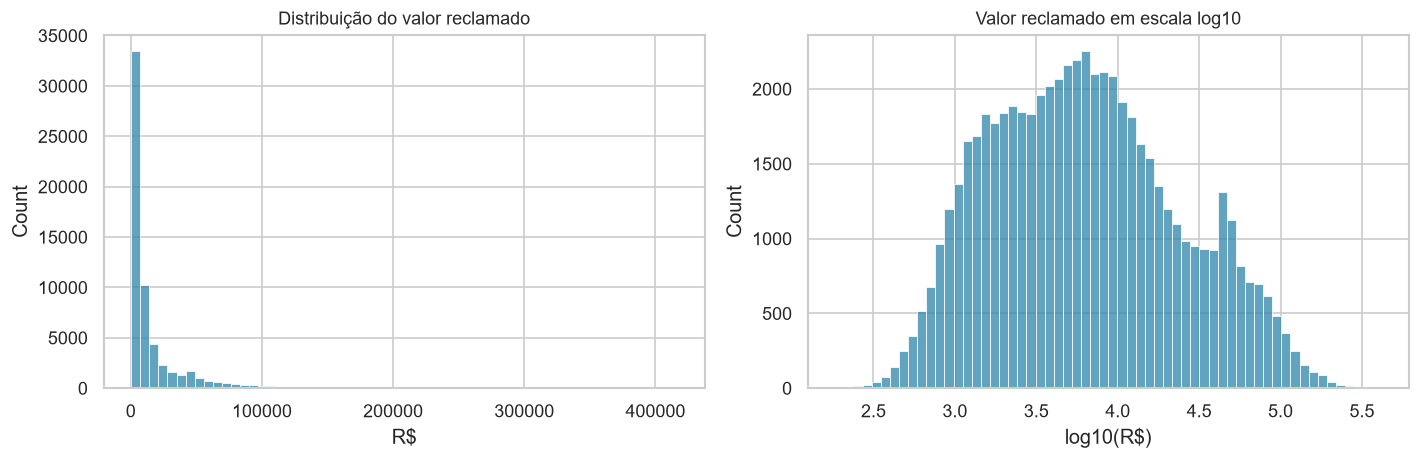

In [25]:
# Figura 2 — distribuição do valor reclamado (escala logarítmica)
fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(base["valor_reclamado"], bins=60, ax=eixos[0], color="#2E86AB")
eixos[0].set_title("Distribuição do valor reclamado")
eixos[0].set_xlabel("R$")
sns.histplot(np.log10(base["valor_reclamado"].clip(lower=1)), bins=60, ax=eixos[1], color="#2E86AB")
eixos[1].set_title("Valor reclamado em escala log10")
eixos[1].set_xlabel("log10(R$)")
plt.tight_layout()
plt.savefig(PASTA_FIGURAS / "02_02_distribuicao_valor_reclamado.png", bbox_inches="tight")
if INTERATIVO:
    plt.show()

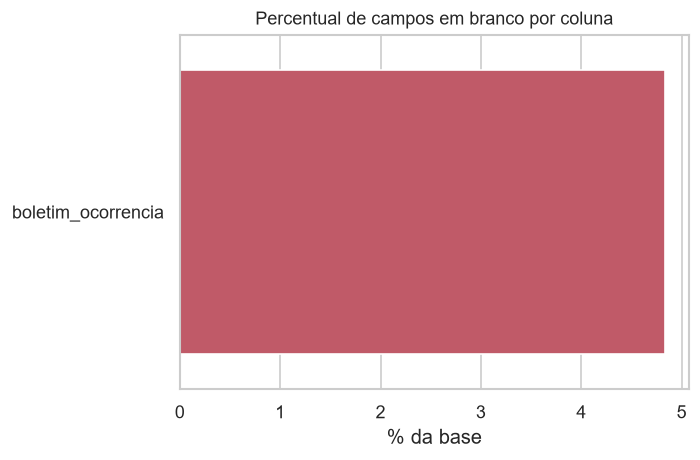

In [26]:
# Figura 3 — campos nulos
fig, eixo = plt.subplots(figsize=(6, 4))
if tabela_nulos.empty:
    eixo.text(0.5, 0.5, "Nenhum campo nulo na base", ha="center", va="center")
    eixo.axis("off")
else:
    sns.barplot(data=tabela_nulos, y="coluna", x="pct_nulos (%)", ax=eixo, color="#D1495B")
    eixo.set_title("Percentual de campos em branco por coluna")
    eixo.set_xlabel("% da base")
    eixo.set_ylabel("")
plt.tight_layout()
plt.savefig(PASTA_FIGURAS / "02_03_campos_nulos.png", bbox_inches="tight")
if INTERATIVO:
    plt.show()

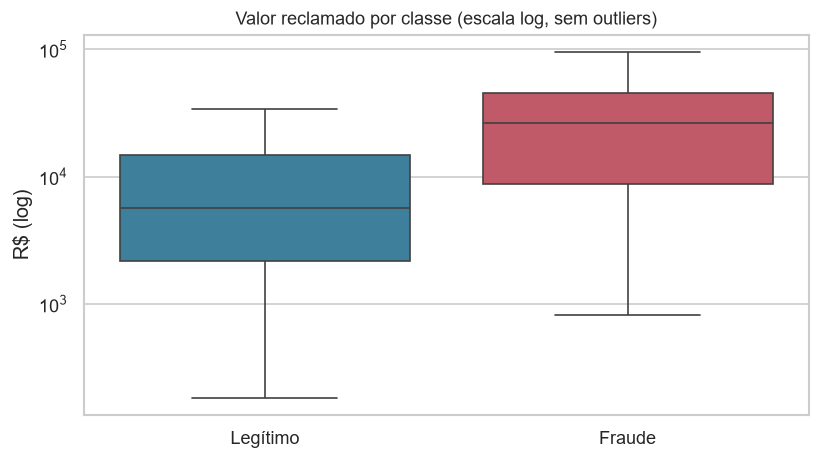


Figuras gravadas em: C:\Users\flavi\Documents\GitHub\Auto-Insurance-Fraud\reports\figures


In [27]:
# Figura 4 — valor reclamado por classe do alvo
fig, eixo = plt.subplots(figsize=(7, 4))
sns.boxplot(data=base.assign(alvo=base["fraude"].map({0: "Legítimo", 1: "Fraude"})),
            x="alvo", y="valor_reclamado", hue="alvo", ax=eixo, showfliers=False,
            legend=False, palette={"Legítimo": "#2E86AB", "Fraude": "#D1495B"})
eixo.set_yscale("log")
eixo.set_title("Valor reclamado por classe (escala log, sem outliers)")
eixo.set_xlabel("")
eixo.set_ylabel("R$ (log)")
plt.tight_layout()
plt.savefig(PASTA_FIGURAS / "02_04_valor_reclamado_por_classe.png", bbox_inches="tight")
if INTERATIVO:
    plt.show()

print(f"\nFiguras gravadas em: {PASTA_FIGURAS}")

## 11. Síntese da fase

In [28]:
resumo = pd.DataFrame(
    [
        ("Linhas x colunas", f"{base_bruta.shape[0]:,} x {base_bruta.shape[1]}"),
        ("Taxa de fraude", f"{taxa_fraude * 100:.2f}% ({n_fraude:,} fraudes)"),
        ("Proporção fraude:legítimo", f"1 : {n_legitimo / n_fraude:.2f}"),
        ("Acurácia do modelo ingênuo", f"{acuracia_dummy * 100:.2f}%"),
        ("Colunas com nulos", ", ".join(tabela_nulos["coluna"]) if not tabela_nulos.empty else "nenhuma"),
        ("Linhas com algum nulo", f"{n_linhas_com_nulo:,} ({n_linhas_com_nulo / len(base_bruta) * 100:.2f}%)"),
        ("Fraudes perdidas se descartar nulos", f"{fraudes_em_linhas_com_nulo:,} "
                                                f"({fraudes_em_linhas_com_nulo / fraudes_totais * 100:.2f}%)"),
        ("Semente do projeto", str(SEED)),
    ],
    columns=["indicador", "valor"],
)
display(resumo)

,indicador,valor
0,Linhas x colunas,"60,000 x 17"
1,Taxa de fraude,"2.47% (1,480 fraudes)"
2,Proporção fraude:legítimo,1 : 39.54
3,Acurácia do modelo ingênuo,97.53%
4,Colunas com nulos,boletim_ocorrencia
5,Linhas com algum nulo,"2,899 (4.83%)"
6,Fraudes perdidas se descartar nulos,94 (6.35%)
7,Semente do projeto,42
